<h3 style="text-align: center;"><b>Лабораторная работа №5</b></h3>

<h3 style="text-align: center;"><b>Сервис синтеза речи</b></h3>

В предыдущих работах у каждого модуля был свой набор данных. Здесь у меня на входе только строка текста. Сначала проверю восстановление звука по настоящей записи, потом подключу модели пауз, транскрипции и акустики и прогоню десять фраз из задания

## Окружение и данные

Запускаю ноутбук из `labs/lab5_service` в ядре окружения `TTS_ITMO_LAB4`. Для нейросетевого вокодера в это окружение добавлен `speechbrain==1.0.3`, для независимой проверки разборчивости - `faster-whisper==1.2.1`. Синтез использует сохранённый FastSpeech2 и предобученный HiFi-GAN из `speechbrain/tts-hifigan-libritts-22050Hz`

In [1]:
from pathlib import Path
from importlib.metadata import version
import os
import re
import sys

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
warnings.filterwarnings('ignore', category=FutureWarning, module=r'speechbrain\.utils\.checkpoints')
warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\.nn\.utils\.weight_norm')
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from io import BytesIO
from IPython.display import Audio, Image, display

lab = Path.cwd()
if (lab / 'labs/lab5_service').is_dir():
    lab = lab / 'labs/lab5_service'
sys.path.insert(0, str(lab))
from tts_pipeline import TTSPipeline, SAMPLE_RATE, SIL, WORD, lookup_key
from check_vocoder import check_vocoder

audio_dir = lab / 'audio'
original = lab.parent / 'lab1_text/data/RUSLAN/000000_RUSLAN.wav'
texts = pd.read_csv(lab / 'data/evaluation_text.csv', sep='|').set_index('id')
assert len(texts) == 10 and texts.index.is_unique
assert torch.cuda.is_available()
print(sys.executable)
print(torch.cuda.get_device_name(0), '| CUDA', torch.version.cuda)
for pkg in ('torch', 'coqui-tts', 'speechbrain', 'spacy', 'ru-core-news-sm', 'scikit-learn', 'faster-whisper'):
    print(pkg, version(pkg))

C:\Users\BKMeI\miniforge3\envs\TTS_ITMO_LAB4\python.exe
NVIDIA GeForce GTX 1060 6GB | CUDA 12.1
torch 2.5.1+cu121
coqui-tts 0.27.5
speechbrain 1.0.3
spacy 3.8.16
ru-core-news-sm 3.8.0
scikit-learn 1.9.1
faster-whisper 1.2.1


## Проверка вокодера на записи RUSLAN

Беру запись "С тревожным чувством берусь я за перо". Считаю по ней mel-спектрограмму с 80 полосами, окном в 1024 отсчёта и шагом 256 отсчётов. Частота дискретизации составляет 22 050 Гц, верхняя граница mel-фильтров - 8000 Гц. При загрузке FastSpeech2 код сверяет параметры выбранного запуска с настройками копи-синтеза. Использую натуральный логарифм с коэффициентом 1, без нормировки mel и обрезки тишины. Подаю одну и ту же матрицу в HiFi-GAN и алгоритм Гриффина-Лима

In [2]:
mel_shape, mel_min, mel_max = check_vocoder(original, audio_dir, device='cuda')
print('Размер mel:', mel_shape, 'диапазон:', round(mel_min, 2), round(mel_max, 2))
def listen(name):
    path = audio_dir / f'{name}.wav'
    print(name, '|', round(sf.info(path).duration, 2), 'с')
    display(Audio(filename=str(path)))

copy_ids = ['natural', 'copysynth_hifigan', 'copysynth_griffinlim']
for name in copy_ids:
    listen(name)

Размер mel: (80, 194) диапазон: -10.24 0.5
natural | 2.24 с


copysynth_hifigan | 2.24 с


copysynth_griffinlim | 2.24 с


## Как я соединил работы №1-4

`Текст → нормализация → токены с пунктуацией → токены с <SIL> → фонемы → mel → WAV`

| Стык | Что получал модуль раньше | Как передаю данные в ЛР5 |
|---|---|---|
| Вход → ЛР1 | Строка корпуса | Вызываю `TextNormalizer.normalize` на одной строке. Сохраняю NFC, "ё" и знак ударения до словарного поиска. Корпусный фильтр ЛР1 исключал целые записи при подготовке обучения, здесь используется только нормализатор |
| ЛР1 → ЛР2 | У предиктора уже были границы слов из MFA и колонка `label_raw` | Выделяю русские слова, присоединяю следующую за словом пунктуацию. Например, запятая остаётся в токене, по которому модель оценивает паузу |
| Ресурсы ЛР2 | Пути к весам отсчитывались от текущего каталога | В `PausePredictor` и `load_predictor` добавил параметр `models_dir`. Передаю каталог весов относительно файла тракта. Выбор модели по-прежнему читается из `selected_pause_model.json` |
| ЛР2 → ЛР3 | ЛР2 возвращала флаг и длительность после каждого слова | После внутреннего слова с положительным флагом вставляю `<SIL>`. Последнее слово при обучении предиктора исключалось. Длительность в секундах сохранять в фонемах негде, число mel-кадров паузы оценивает FastSpeech2 |
| Вход ЛР3 | Слова из подготовленной таблицы | Снимаю краевую пунктуацию, для словарного ключа использую нижний регистр и убираю только знак ударения. Передаю пути к словарям явно. Выбран режим `final`: словарь корпуса, затем Russian MFA, затем правила для незнакомого слова. Для незнакомого слова с дефисом проверяю его части |
| ЛР3 → ЛР4 | G2P выдаёт список фонем для каждого слова, FastSpeech2 обучался на строке | Сохраняю `<SIL>`, разворачиваю вложенные списки и проверяю фонемы по инвентарю. Между соседними фонемами ставлю пробел, поэтому многосимвольная фонема остаётся одним элементом |
| Загрузка ЛР4 | В `config.json` выбранного запуска поле `characters` равно `null` | При загрузке восстанавливаю `MulticharPhonemes` из `common/phones_mfa.txt` с теми же специальными символами и порядком, что в `evaluate.py` ЛР4. Загружаю выбранные веса `baseline_gt`. Набор входных фонем у двух запусков общий |
| ЛР4 → вокодер | В ЛР4 mel восстанавливался через Гриффина-Лима | Переставляю оси выхода FastSpeech2 и подаю в HiFi-GAN тензор формы `[1, 80, T]` на CUDA. После декодирования убираю с каждого края по 5 добавленных вокодером кадров (1280 отсчётов), чтобы они не попадали в стыки фрагментов. Результат перевожу в одномерный массив и сохраняю с частотой 22 050 Гц |

Модели, словари и русский анализатор spaCy загружаю один раз. Для длинного входа предсказываю паузы по всей фразе, затем делю последовательность на группы примерно по 18 токенов. Предпочитаю границу на паузе или знаке препинания, а при их отсутствии делю между словами. Для каждой группы считаю mel, озвучиваю его и соединяю фрагменты в исходном порядке

#### Выбор весов FastSpeech2

На первых четырёх фразах из `lab4_acoustic/data/eval_sentences.csv` проверил оба сохранённых варианта. Каждому передавал исходный текст через один и тот же нормализатор и G2P, эталонную колонку фонем не использовал. Звук распознавал Whisper small на CUDA с русским языком и шириной поиска 3. В таблице число замен, пропусков и вставок относительно исходных слов

| Запись RUSLAN | Слов | G2P, шаг 114480 | GT, шаг 515160 |
|---|---:|---:|---:|
| 000020 | 8 | 3 | 4 |
| 000080 | 4 | 4 | 0 |
| 000395 | 9 | 3 | 1 |
| 000815 | 6 | 1 | 0 |

Для десяти тестовых фраз выбираю GT. В этой небольшой проверке у него 5 ошибок на 27 словах против 11 у G2P. Два предложения с GT распознаны целиком. Запуски различаются и обучающими транскрипциями, и числом шагов, поэтому по такой проверке нельзя выделить вклад одной лишь MFA-разметки

In [3]:
pipeline = TTSPipeline(device='cuda')
print('Акустическая модель:', pipeline.checkpoint.name, next(pipeline.model.parameters()).device)
print('Вокодер:', next(pipeline.vocoder.mods.generator.parameters()).device)
print('Предиктор пауз:', pipeline.pauses.approach)
print('Размер инвентаря:', len(pipeline.phone_set))

sample = 'Здравствуйте, ваш заказ готов!'
tokens = pipeline.tokenize(pipeline.normalize(sample))
paused = pipeline.insert_pauses(tokens)
phones = pipeline.to_phones(paused)
print('Токены:', tokens)
print('После ЛР2:', paused)
print('Фонемы:', ' '.join(phones))
assert SIL in pipeline.to_phones(['да', SIL, 'нет'])
warmup, _ = pipeline(sample)
assert len(warmup) and np.isfinite(warmup).all()

Russian MFA: загружено 452359 слов / 470057 вариантов
Пропущено вариантов с фонемами вне phones_mfa.txt: 41


Акустическая модель: best_model_515160.pth cuda:0
Вокодер: cuda:0
Предиктор пауз: morph_syntax
Размер инвентаря: 56
Токены: ['Здравствуйте,', 'ваш', 'заказ', 'готов!']
После ЛР2: ['Здравствуйте,', 'ваш', 'заказ', 'готов!']
Фонемы: z̪ d̪ r a s̪ t̪ v ʊ j tʲ e v a ʂ z̪ ɐ k a s̪ ɡ ɐ t̪ o f


## Что делать с неподдерживаемым вводом

Проверю пустой ввод, пунктуацию без слов и строку с латиницей. Ошибку можно перехватить до передачи текста в FastSpeech2

In [4]:
for sample in ('   ', '?!', 'слово fabric', 'в 1800-х', 'А + Б'):
    try:
        signal, _ = pipeline(sample)
        print(repr(sample), '-> отсчётов:', len(signal))
    except ValueError as error:
        print(repr(sample), '->', error)

'   ' -> отсчётов: 0
'?!' -> отсчётов: 0
'слово fabric' -> Запишите словами неподдерживаемые символы: a b c f i r
'в 1800-х' -> Запишите словами неподдерживаемые символы: 0 1 8
'А + Б' -> Запишите словами неподдерживаемые символы: +


## Десять фраз из задания

Сначала проверяю, проходит ли исходная строка через нормализацию и токенизацию. Для трёх входов записываю произносимый вариант в отдельном столбце. В `eval_08` передаю английские слова русскими буквами, в `eval_09` раскрываю "1800-х" в предложном падеже. В `eval_10` называю плюс и знак равенства, читаю "ТВ" по буквам, косые черты и кавычки трактую как разделители. Это выбранное прочтение неоднозначной записи

In [5]:
texts['spoken'] = texts.text.copy()
def adapt(key, changes):
    value = texts.at[key, 'text']
    for before, after in changes:
        assert before in value
        value = value.replace(before, after)
    texts.at[key, 'spoken'] = ' '.join(value.split())

adapt('eval_08', [('fabric', 'фэбрик'), ('details', 'дитейлз')])
adapt('eval_09', [('1800-х', 'тысяча восьмисотых')])
adapt('eval_10', [('‹‹', ''), ('+', ' плюс '), ('=', ' равно '), ('::', ', '),
                  ('ТВ', 'тэ вэ'), ('//', ''), ('/', ', ')])
display(texts.loc[texts.text != texts.spoken, ['text', 'spoken']])
for key, row in texts.iterrows():
    try:
        pipeline.tokenize(pipeline.normalize(row.text))
        reason = 'принята'
    except ValueError as error:
        reason = str(error)
    print(key, reason)
    if row.text != row.spoken:
        print('  Первые слова после адаптации:', ' '.join(row.spoken.split()[:12]))

,text,spoken
id,,
eval_08,"Смотря какой fabric, смотря сколько details в ...","Смотря какой фэбрик, смотря сколько дитейлз в ..."
eval_09,"В 1800-х годах, в те времена, когда не было ещ...","В тысяча восьмисотых годах, в те времена, когд..."
eval_10,‹‹Записываю витал-икону+наши хромосомы из выде...,Записываю витал-икону плюс наши хромосомы из в...


eval_01 принята
eval_02 принята
eval_03 принята
eval_04 принята
eval_05 принята
eval_06 принята
eval_07 принята
eval_08 Запишите словами неподдерживаемые символы: a b c f i r
  Первые слова после адаптации: Смотря какой фэбрик, смотря сколько дитейлз в этом пиджаке
eval_09 Запишите словами неподдерживаемые символы: 0 1 8
  Первые слова после адаптации: В тысяча восьмисотых годах, в те времена, когда не было еще ни
eval_10 Запишите словами неподдерживаемые символы: ‹
  Первые слова после адаптации: Записываю витал-икону плюс наши хромосомы из выделений в присос равно кровь хромосомы,


## Скорость синтеза

Прогрев уже прошёл на отдельной строке. Каждую тестовую фразу синтезирую один раз. Время этапов включает перенос результата нейросети в память CPU. Загрузка моделей и запись WAV на диск в замеры не входят. Делением суммы времён на длительность WAV получаю RTF

In [6]:
rows = []
for key, row in texts.iterrows():
    wav, timing = pipeline(row.spoken)
    assert wav.size and np.isfinite(wav).all() and np.max(np.abs(wav)) > 0
    pipeline.save(wav, audio_dir / f'{key}.wav')
    rows.append(dict(id=key, words=len(pipeline.tokenize(pipeline.normalize(row.spoken))),
                     chunks=timing.chunks, audio_s=timing.audio_seconds, total_s=timing.total,
                     RTF=timing.rtf, **{k: v * 1000 for k, v in timing.stages.items()}))

times = pd.DataFrame(rows).set_index('id')
display(times[['words', 'chunks', 'audio_s', 'total_s', 'RTF']].round(3))
stages = ['normalize', 'tokenize', 'pauses', 'g2p', 'acoustic', 'vocoder']
display(times[stages].round(2).rename_axis('Время, мс'))
print('RTF по сумме времён:', round(times.total_s.sum() / times.audio_s.sum(), 3))

,words,chunks,audio_s,total_s,RTF
id,,,,,
eval_01,14,1,4.296,0.185,0.043
eval_02,9,1,2.183,0.111,0.051
eval_03,13,1,8.719,0.321,0.037
eval_04,7,1,3.692,0.155,0.042
eval_05,10,1,4.331,0.173,0.040
eval_06,10,1,4.389,0.181,0.041
eval_07,6,1,1.625,0.083,0.051
eval_08,9,1,3.413,0.140,0.041
eval_09,190,15,79.029,3.066,0.039


,normalize,tokenize,pauses,g2p,acoustic,vocoder
"Время, мс",,,,,,
eval_01,0.04,0.02,10.62,0.13,23.19,150.61
eval_02,0.02,0.01,15.99,0.07,17.02,77.92
eval_03,0.05,0.02,9.50,0.37,28.27,282.59
eval_04,0.03,0.01,9.03,0.12,20.92,124.48
eval_05,0.03,0.01,6.64,0.06,22.16,143.69
eval_06,0.03,0.01,9.32,0.07,21.08,150.01
eval_07,0.03,0.01,7.17,0.09,14.03,61.93
eval_08,0.08,0.04,7.37,0.10,20.63,111.99
eval_09,0.29,0.14,54.09,1.89,331.79,2678.11


RTF по сумме времён: 0.039


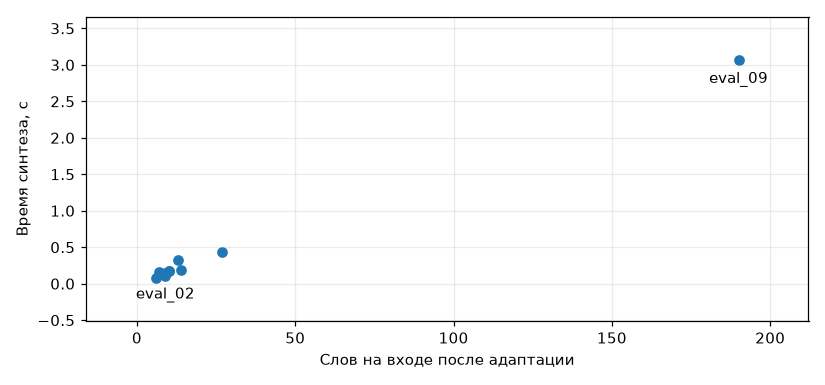

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.scatter(times.words, times.total_s)
for key in ['eval_02', 'eval_09']:
    row = times.loc[key]
    ax.annotate(key, (row.words, row.total_s), xytext=(0, -15), textcoords='offset points', ha='center')
ax.set(xlabel='Слов на входе после адаптации', ylabel='Время синтеза, с')
ax.margins(x=.12, y=.2)
ax.grid(alpha=.25)
plt.tight_layout()
out = BytesIO()
fig.savefig(out, format='png', dpi=110)
plt.close(fig)
display(Image(data=out.getvalue()))

У короткой `eval_07` шесть слов и 0,083 с на синтез. Для `eval_09` с 190 словами потребовалось 3,066 с на 15 фрагментов. На одних только словах время предсказать трудно. У `eval_03` всего 13 слов, но среди них есть длинные имена. Она дала 8,72 с звука, а `eval_01` из 14 слов - 4,30 с

На всех фразах вместе HiFi-GAN занял 4,16 с из примерно 4,85 с измеренного времени, то есть около 86 %. Это замер одного прогретого запуска на GTX 1060. При другом размере фразы и нагрузке GPU цифры могут измениться

## Проверка качества

Для копи-синтеза можно сравнить два сигнала с одной и той же записью. Измеряю разницу log-mel на общих кадрах после выравнивания пиковых амплитуд. Эта величина показывает расхождение спектров, а произношение и естественность удобнее сравнить в плеерах выше

In [8]:
def read_mel(name):
    signal, sr = sf.read(audio_dir / f'{name}.wav', dtype='float32')
    assert sr == SAMPLE_RATE
    signal /= max(np.max(np.abs(signal)), 1e-8)
    return pipeline.ap.melspectrogram(signal)

natural_mel = read_mel('natural')
for name in copy_ids[1:]:
    mel = read_mel(name)
    n = min(mel.shape[1], natural_mel.shape[1])
    error = np.abs(mel[:, :n] - natural_mel[:, :n]).mean()
    print(name, '| общих кадров:', n, '| MAE log-mel:', round(float(error), 3))

copysynth_hifigan | общих кадров: 194 | MAE log-mel: 0.239
copysynth_griffinlim | общих кадров: 194 | MAE log-mel: 2.181


На всех 194 общих кадрах средняя абсолютная ошибка log-mel у HiFi-GAN равна 0,239, у Гриффина-Лима - 2,181. После удаления служебного дополнения HiFi-GAN длительность его WAV совпала с оригиналом до отсчёта (49 497 отсчётов). По этим измерениям HiFi-GAN точнее сохранил спектр контрольной фразы. Оценку сходства тембра на слух оставляю открытой, обе записи для сравнения встроены в начало отчёта

Для тестовых текстов нет эталонных записей. Посмотрю, какие слова из WAV может восстановить независимый распознаватель Whisper small. Я задаю ему русский язык и передаю только аудио. WER считаю по словам после приведения к нижнему регистру, замены "ё" на "е" и замены пунктуации пробелами. Написания "1800-х" и "тысяча восьмисотых" привожу к общей форме. В качестве эталона беру текст, фактически переданный в синтезатор. Ошибка распознавателя тоже попадает в эту оценку

In [9]:
from faster_whisper import WhisperModel
from labs.lab3_g2p.g2p import edit_distance

torch.cuda.empty_cache()
os.environ['PATH'] = str(Path(torch.__file__).parent / 'lib') + os.pathsep + os.environ['PATH']
asr = WhisperModel('small', device='cuda', compute_type='float32', local_files_only=os.environ.get('HF_HUB_OFFLINE') == '1')
def recognize(name):
    segments, _ = asr.transcribe(str(audio_dir / f'{name}.wav'), language='ru',
                                 beam_size=3, condition_on_previous_text=False)
    return ' '.join(s.text.strip() for s in segments).strip()

def words_for_wer(text):
    text = re.sub(r'\b1800[- ]?х\b', 'тысяча восьмисотых', text.lower())
    return re.findall('[а-я]+|[a-z]+|[0-9]+', text.replace('ё', 'е'))

scores = []
for name in copy_ids + list(texts.index):
    reference = texts.at[name, 'spoken'] if name in texts.index else 'С тревожным чувством берусь я за перо'
    hypothesis = recognize(name)
    words = words_for_wer(reference)
    errors = edit_distance(words, words_for_wer(hypothesis))
    scores.append(dict(id=name, reference=reference, recognized=hypothesis, words=len(words),
                       errors=errors, WER=errors / len(words)))
scores = pd.DataFrame(scores).set_index('id')
with pd.option_context('display.max_colwidth', 100):
    display(scores[['recognized', 'words', 'errors', 'WER']].round(3))

,recognized,words,errors,WER
id,,,,
natural,С тревожным чувством берусь я за пером.,7,1,0.143
copysynth_hifigan,С тревожным чувством берусь я за пером.,7,1,0.143
copysynth_griffinlim,С тревожным чувством берусь я за пером.,7,1,0.143
eval_01,"Мы всем отрядом съели все, что было во всем лаге, и все остались довольны.",14,1,0.071
eval_02,А он что? Да ты что? Вот оно что.,9,0,0.000
eval_03,"Когда в Шелпу-Али наступает талакоши пиволицли, Мешик и Ночтетлана славят шипе-тотека. Кицелька ...",14,12,0.857
eval_04,Батмен сезисно синтезировал анамную супермена на компьютере.,7,3,0.429
eval_05,"Хорошо и зимнюю в югу все траканы передохнут, а люди передохнут.",10,5,0.500
eval_06,"Убых тупо губ, тупо губенький бычок, у боковела губа была тупа.",10,7,0.700


Для проверки ударений сравню два вхождения "передохнут" в `eval_05`. В `eval_03` посмотрю, откуда G2P берёт произношение редких имён

In [10]:
for key in ('eval_03', 'eval_05'):
    tokens = pipeline.tokenize(pipeline.normalize(texts.at[key, 'spoken']))
    for token in tokens:
        word = lookup_key(WORD.match(token).group())
        if key == 'eval_05' and word != 'передохнут':
            continue
        print(word, pipeline.g2p.source(word), ' '.join(pipeline.to_phones([token])))

когда corpus k ɐ ɡ d̪ a
в corpus v
шиупоуалли oov ʂ ɨ ʊ p ə ʊ a ʎ ɪ
наступает corpus n̪ ə s̪ t̪ ʊ p a j ɪ t̪
тлакашипеуалицтли oov t̪ ɫ ə k ə ʂ ɨ pʲ ɪ ʊ ɐ ʎ i t̪s̪ t̪ ʎ ɪ
мешика oov mʲ e ʂ ɨ k ə
теночтитлана oov tʲ ɪ n̪ ə tɕ tʲ ɪ t̪ ɫ a n̪ ə
славят mfa s̪ ɫ a vʲ ə t̪
шипе-тотека oov ʂ ɨ pʲ e t̪ ɐ tʲ e k ə
кецалькоатля oov c ɪ t̪s̪ ə ʎ k ɐ a t̪ ʎ ɪ
уицилопочтли oov ʊ ɪ t̪s̪ ɨ ɫ ɐ p o tɕ t̪ ʎ ɪ
и corpus i
тескатлипоку oov tʲ ɪ s̪ k ə t̪ ʎ ɪ p o k ʊ
передохнут mfa pʲ ɪ rʲ ɪ d̪ ɐ x n̪ u t̪
передохнут mfa pʲ ɪ rʲ ɪ d̪ ɐ x n̪ u t̪


Оба "передохнут" получили одну словарную транскрипцию с ударным последним слогом. Пауза перед "а люди" появилась. Для прочтения "тараканы погибнут, а люди отдохнут" нужны разные ударения. В первом случае это "передо́хнут", во втором - "передохну́т". В этом месте ошибка возникает уже при выборе произношения в ЛР3

Для восьми из тринадцати токенов `eval_03` целое слово отсутствует в обоих словарях. На этой фразе Whisper сделал 12 правок на 14 словах после разделения дефисов. Даже при правильном произношении редкое имя трудно распознать, поэтому все 12 ошибок нельзя приписать G2P

На короткой `eval_02` предиктор поставил паузы после "что?" и "что!". Whisper восстановил все девять слов, но поставил вопросительный знак и после второй реплики. WER игнорирует пунктуацию и здесь ничего не говорит о вопросительной или восклицательной интонации

In [11]:
for name in texts.index:
    listen(name)

eval_01 | 4.3 с


eval_02 | 2.18 с


eval_03 | 8.72 с


eval_04 | 3.69 с


eval_05 | 4.33 с


eval_06 | 4.39 с


eval_07 | 1.63 с


eval_08 | 3.41 с


eval_09 | 79.03 с


eval_10 | 11.38 с


## Выводы

На CUDA получил 123,05 с звука за 4,85 с работы тракта после прогрева. Суммарный RTF равен 0,039. Во всех десяти случаях результат сохранился как моно WAV с частотой 22 050 Гц. Для семи фраз подошёл исходный текст, для трёх потребовалась запись числительного, иностранных слов или символов в произносимой форме

У Whisper small получилось 78 правок на 310 словах, WER по всему набору равен 25,2 %. Большой вес в этой цифре имеет длинная `eval_09` с 193 словами для подсчёта WER. Токенизатор модели пауз оставляет составные слова с дефисом вместе, поэтому в таблице времени для неё 190 слов. У `eval_01` восстановились 13 слов из 14, у `eval_08` расхождения пришлись как раз на две английские вставки. На скороговорке `eval_06` распознаватель несколько раз разделил одно слово на два

У оригинала и двух вариантов копи-синтеза распознаватель одинаково заменил "перо" на "пером". На этой записи автоматическая проверка слов не различила вокодеры. Разницу в сохранении спектра показало сравнение log-mel. Для тестовых фраз сравнить спектр с эталонной записью нельзя, поэтому в отчёте оставлены сами WAV, распознанный текст и разбор конкретных фонем и пауз

## Дополнительные задания

### Telegram-бот для синтеза речи

Для голосовых ответов подключил готовый тракт ЛР5 к Telegram через `python-telegram-bot`. 
Скрипт [telegram_bot.py](./telegram_bot.py) лежит рядом с текущим отчетом в `labs/lab5_service/`. При запуске он один раз загружает модели на CUDA, а затем озвучивает входящие фразы и отправляет результат голосовым сообщением в формате OGG/Opus

**Как запустить**

1. В Telegram открыть [@BotFather](https://t.me/BotFather), отправить `/newbot`, выбрать имя и свободный username с окончанием `bot`. BotFather пришлёт токен и ссылку на бота
2. Из корня проекта `LABS` выполнить

   ```powershell
   python .\labs\lab5_service\telegram_bot.py
   ```

3. Вставить токен по запросу терминала и нажать Enter.
   
   Когда появится сообщение "Модели готовы", открыть бота по ссылке.\
   Для остановки нажать Ctrl+C

**Пример общения с ботом**\
Мой ботик валяется на @tts_lab5_bot, для запуска напишите в ЛС, к окончании сдачи ЛР - удалю бота )

![Текст запроса и голосовой ответ Telegram-бота (1)](./1.png)
![Текст запроса и голосовой ответ Telegram-бота (2)](./2.png)